# Intensity Transformations & Filtering Spatial Domain

## Thresholding

Threshold value: 0


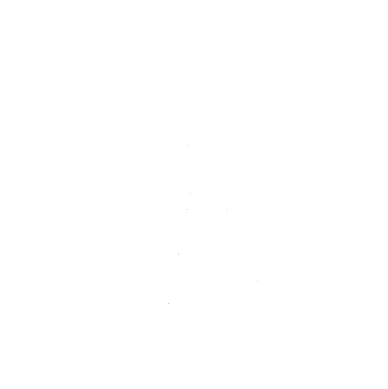

Threshold value: 50


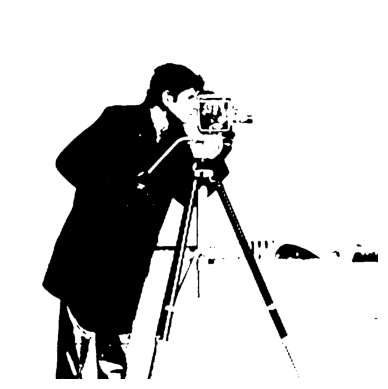

Threshold value: 100


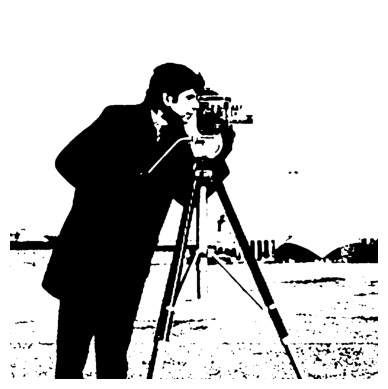

Threshold value: 150


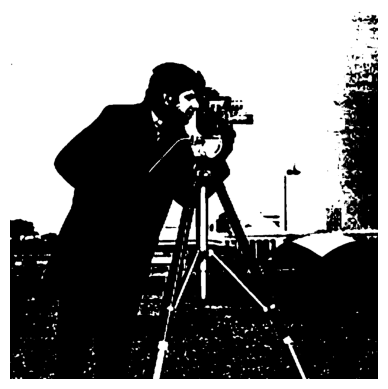

Threshold value: 200


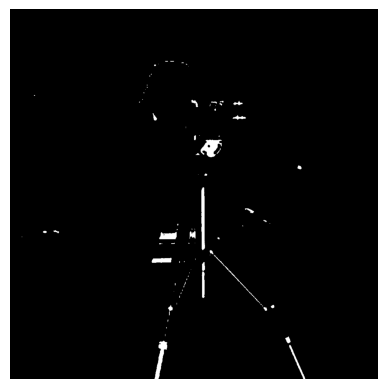

In [1]:
import cv2
import matplotlib.pyplot as plt

# NOTE: cv2_imshow() is a Google Colab-only helper. Running outside Colab (like here),
# we use a small local replacement so the rest of the code stays identical to the lab.
def cv2_imshow(image):
    plt.figure()
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.show()

# Load the image in grayscale
img = cv2.imread('cameraman.png', cv2.IMREAD_GRAYSCALE)

# Set the threshold values
threshold_values = [0, 50, 100, 150, 200]

# Apply thresholding with different threshold values
for threshold_value in threshold_values:
    ret_thresh_value, thresh_img = cv2.threshold(img, threshold_value, 255, cv2.THRESH_BINARY)

    print(f"Threshold value: {threshold_value}")
    cv2_imshow(thresh_img)

Original Image: 


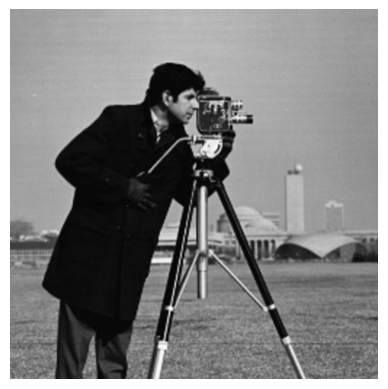

In [3]:
print("Original Image: ")
cv2_imshow(img)

## Histograms

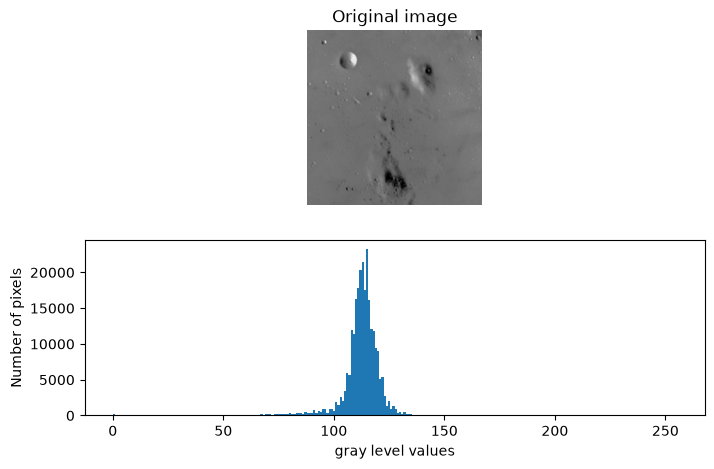

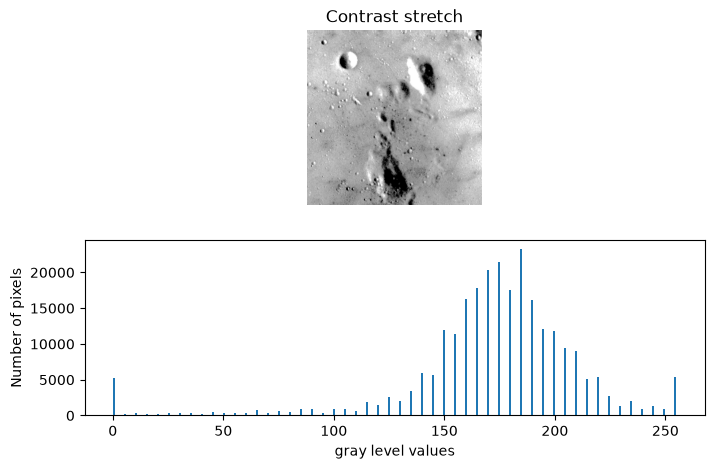

In [4]:
# Task#2: Histogram Processing

# Step#1: Load necessary libraries
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from skimage import data
from skimage import exposure

# Step#2: Load moon image
img = data.moon()

# Step#3: Rescale intensity values to include all the intensities that fall within the 2nd and 98th percentiles
# Contrast stretching
p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

# Step#4: Display the image with its histogram of (step#2)  and (step#3)
fig = plt.figure(figsize=(8, 5))
fig.add_subplot(2, 1, 1)
plt.imshow(img, cmap = 'gray')
plt.axis('off')
plt.title('Original image')

fig.add_subplot(2, 1, 2)
plt.hist(img.flat, bins = 256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

fig = plt.figure(figsize=(8, 5))
fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale, cmap = 'gray')
plt.axis('off')
plt.title('Contrast stretch')

fig.add_subplot(2, 1, 2)
plt.hist(img_rescale.flat, bins = 256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

# Tasks:

Task1: Using the same ‘moon image’ Rescale intensity values to include all the intensities that fall within the 3nd and 80th percentiles, and plot the histogram

Task2: Using the same ‘moon image’ and the exposure.equalize_hist function, display the image and the histogram of the image after flattening the histogram.

Task3: Use the rocket (as reference) and chelsea images (from skimage.data) and implement histogram matching


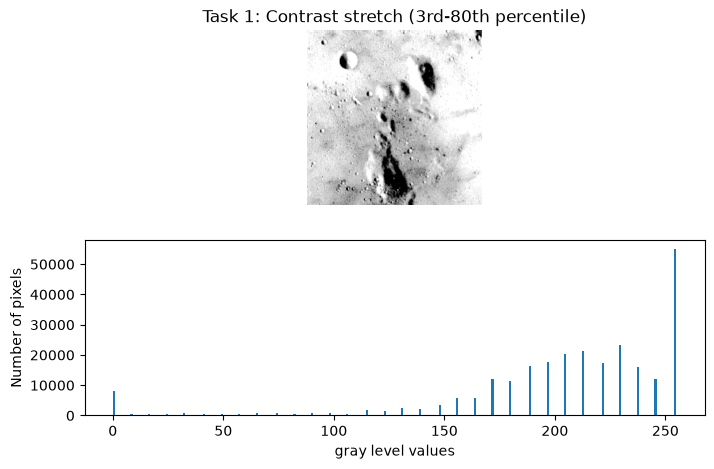

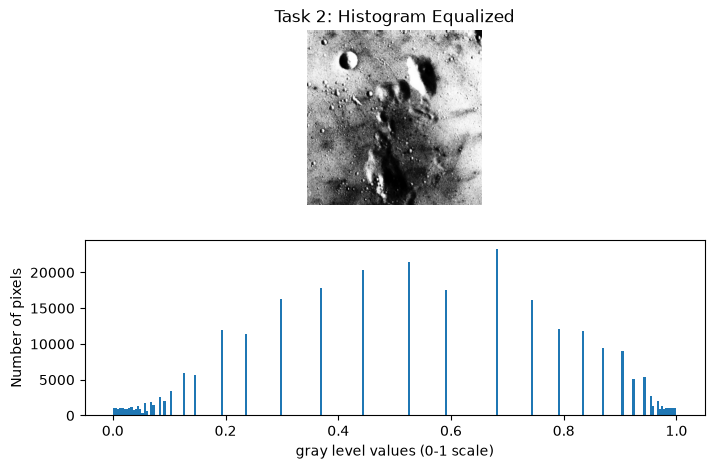

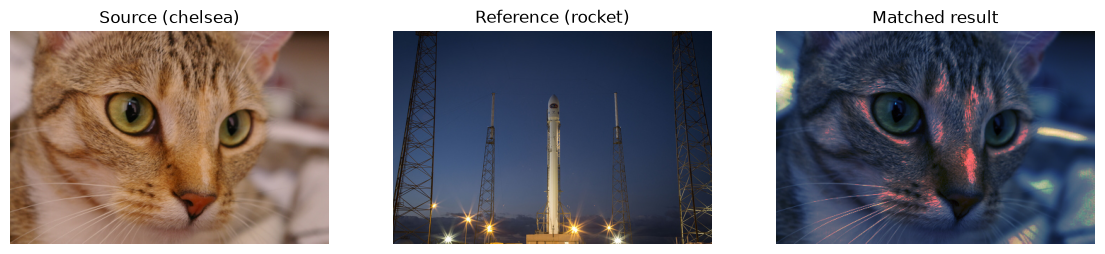

In [6]:
# ============================================================
# Task 1: Rescale intensity using the 3rd and 80th percentiles
# ============================================================
moon_img = data.moon()

p3, p80 = np.percentile(moon_img, (3, 80))
img_rescale_t1 = exposure.rescale_intensity(moon_img, in_range=(p3, p80))

fig = plt.figure(figsize=(8, 5))
fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale_t1, cmap='gray')
plt.axis('off')
plt.title('Task 1: Contrast stretch (3rd-80th percentile)')

fig.add_subplot(2, 1, 2)
plt.hist(img_rescale_t1.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()


# ============================================================
# Task 2: Histogram equalization using exposure.equalize_hist
# ============================================================
img_eq_t2 = exposure.equalize_hist(moon_img)

fig = plt.figure(figsize=(8, 5))
fig.add_subplot(2, 1, 1)
plt.imshow(img_eq_t2, cmap='gray')
plt.axis('off')
plt.title('Task 2: Histogram Equalized')

fig.add_subplot(2, 1, 2)
plt.hist(img_eq_t2.flat, bins=256, range=(0, 1))
plt.xlabel('gray level values (0-1 scale)')
plt.ylabel('Number of pixels')
plt.show()


# ============================================================
# Task 3: Histogram matching (chelsea matched to rocket's colors)
# ============================================================
from skimage.exposure import match_histograms

reference_img = data.rocket()     # the image whose color/tone distribution we want to copy
source_img = data.chelsea()       # the image we want to adjust

matched_img = match_histograms(source_img, reference_img, channel_axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(source_img)
axes[0].set_title('Source (chelsea)')
axes[0].axis('off')

axes[1].imshow(reference_img)
axes[1].set_title('Reference (rocket)')
axes[1].axis('off')

axes[2].imshow(matched_img)
axes[2].set_title('Matched result')
axes[2].axis('off')
plt.show()